# Quantum Forest Planning — Experiments (DatZD028, Project 2)
**Muhammad Sajjad Hossain, University of Latvia, 2026**

This notebook reproduces the experiments in survey version 4. It runs in **Google Colab**, so nothing needs to be installed on your computer.

**How to run:** press **Runtime → Run all**, or click the ▶ button on each cell from top to bottom. Each cell prints its results and draws its charts below it.

| Part | What it shows | Approx. time |
|---|---|---|
| 1 | One 12-stand forest solved by all methods | ~1 min |
| 2 | Classical results matrix (success ratio, quality, time) | ~1 min |
| 3 | Complexity: how the even-flow rule makes exact solving hard | ~2–3 min |
| 4 | Quantum methods averaged over several forests | ~2–4 min |
| 5 | Coupling growth: sparse vs dense (even flow) | seconds |
| 6 | *Optional:* check the QAOA simulation against Qiskit | ~1 min |

Quantum methods are **simulated exactly on a normal computer** (no real quantum hardware, no noise).

In [1]:
# Setup: libraries (all pre-installed in Google Colab)
import time, itertools, warnings
warnings.filterwarnings('ignore')
import numpy as np, networkx as nx, matplotlib.pyplot as plt
from scipy.optimize import milp, LinearConstraint, Bounds, minimize
from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.linalg import expm_multiply
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
print('Ready.')

Ready.


## Helper functions
**Forest model:** stands are placed at random; two stands are neighbours if they are close (4–5 neighbours each). Each stand has a timber volume of 50–300 m³.

**Problem:** choose stands to harvest, with **no two neighbours cut together**, to maximise volume. This is the *maximum weighted independent set* problem. As a QUBO the cost is: −(value of chosen stands) + P × (number of neighbour pairs both chosen).

In [2]:
def make_forest(n, seed, mean_degree=5.0):
    """Random forest: n stands, neighbours = stands closer than a radius."""
    r = np.sqrt(mean_degree / (np.pi * n))
    g = nx.random_geometric_graph(n, r, seed=seed)
    vol = np.round(np.random.default_rng(seed + 1000).uniform(50, 300, n))
    return g, vol

def small_forest(n, seed):
    """Connected small forest for the quantum tests."""
    rng = np.random.default_rng(seed)
    while True:
        pos = rng.random((n, 2))
        g = nx.random_geometric_graph(n, 0.42, pos={i: pos[i] for i in range(n)})
        if nx.is_connected(g) and 3.0 <= 2 * g.number_of_edges() / n <= 5.0:
            return g, np.round(rng.uniform(50, 300, n)), pos

def is_valid(g, x):
    return all(not (x[i] and x[j]) for i, j in g.edges())

# ---------- classical methods ----------
def exact_milp(g, w, time_limit=60):
    """Exact solver (mixed-integer programming, HiGHS)."""
    n, E = g.number_of_nodes(), list(g.edges())
    A = lil_matrix((max(len(E), 1), n))
    for k, (i, j) in enumerate(E): A[k, i] = 1; A[k, j] = 1
    t = time.perf_counter()
    r = milp(-w, constraints=[LinearConstraint(csr_matrix(A), -np.inf, 1)],
             integrality=np.ones(n), bounds=Bounds(0, 1), options={'time_limit': time_limit})
    return np.round(r.x).astype(int), time.perf_counter() - t

def greedy(g, w):
    t = time.perf_counter(); x = np.zeros(len(w), int); blocked = set()
    for i in sorted(range(len(w)), key=lambda i: -w[i] / (g.degree(i) + 1)):
        if i not in blocked:
            x[i] = 1; blocked |= set(g.neighbors(i)) | {i}
    return x, time.perf_counter() - t

def simulated_annealing(g, w, P, sweeps, rng):
    n = len(w); nb = [np.array(list(g.neighbors(i)), int) for i in range(n)]
    t = time.perf_counter(); x = rng.integers(0, 2, n)
    for k in range(sweeps):
        T = 2.0 * (0.01 / 2.0) ** (k / sweeps)
        for i in rng.permutation(n):
            d = (1 - 2 * x[i]) * (-w[i] + P * x[nb[i]].sum())
            if d < 0 or rng.random() < np.exp(-d / T): x[i] ^= 1
    return x, time.perf_counter() - t

def tabu_search(g, w, P, iters, tenure=None):
    n = len(w); nb = [np.array(list(g.neighbors(i)), int) for i in range(n)]
    tenure = tenure or max(5, n // 10)
    t = time.perf_counter(); x = np.zeros(n, int)
    delta = np.array([-w[i] for i in range(n)], float); E = 0.0
    best, bestE = x.copy(), 0.0; tl = np.zeros(n, int)
    for it in range(iters):
        cand = np.where((tl <= it) | (E + delta < bestE - 1e-12))[0]
        i = cand[np.argmin(delta[cand])]
        E += delta[i]; x[i] ^= 1; tl[i] = it + tenure; delta[i] = -delta[i]
        s = 1 if x[i] else -1
        for j in nb[i]: delta[j] += (1 - 2 * x[j]) * P * s
        if E < bestE - 1e-12: bestE, best = E, x.copy()
    return best, time.perf_counter() - t

# ---------- quantum methods (exact simulation) ----------
def all_plans(N):
    return np.array([[(k >> q) & 1 for q in range(N)] for k in range(2 ** N)])

def qaoa_state(theta, cost, p, N):
    """QAOA: start in equal superposition, apply p layers of cost + mixer."""
    psi = np.full(2 ** N, 2 ** (-N / 2), dtype=complex)
    for l in range(p):
        psi = psi * np.exp(-1j * theta[l] * cost)                      # cost step (gamma)
        c, s = np.cos(theta[p + l]), -1j * np.sin(theta[p + l])        # mixer step (beta)
        psi = psi.reshape([2] * N)
        for q in range(N):
            a0, a1 = np.take(psi, 0, axis=q), np.take(psi, 1, axis=q)
            psi = np.stack([c * a0 + s * a1, s * a0 + c * a1], axis=q)
        psi = psi.reshape(-1)
    return psi

def run_qaoa(cost, N, p, rng, warm=None, restarts=6):
    """Optimise the 2p QAOA angles with COBYLA; return output probabilities."""
    f = lambda th: float(np.abs(qaoa_state(th, cost, p, N)) ** 2 @ cost)
    starts = [np.concatenate([rng.uniform(0, 1, p), rng.uniform(0, np.pi / 2, p)]) for _ in range(restarts)]
    if warm is not None:   # reuse angles from depth p-1
        starts.insert(0, np.concatenate([np.append(warm[:p - 1], warm[p - 2]), np.append(warm[p - 1:], warm[-1])]))
    best = min((minimize(f, x0, method='COBYLA', options={'maxiter': 400}) for x0 in starts), key=lambda r: r.fun)
    return np.abs(qaoa_state(best.x, cost, p, N)) ** 2, best.x

def rydberg_sweep(g, w, T_total, steps=200, Omega=1.0, Dmax=3.0):
    """Neutral-atom (Rydberg) adiabatic sweep. The blockade forbids neighbours being
    excited together, so we simulate only valid plans (independent sets)."""
    N, E = len(w), list(g.edges())
    states = [k for k in range(2 ** N) if all(not ((k >> i) & 1 and (k >> j) & 1) for i, j in E)]
    pos = {s: a for a, s in enumerate(states)}; M = len(states)
    X = lil_matrix((M, M))
    for a, s in enumerate(states):
        for i in range(N):
            t = s ^ (1 << i)
            if t in pos: X[a, pos[t]] = 0.5
    X = csr_matrix(X)
    value = np.array([sum(w[i] for i in range(N) if (s >> i) & 1) for s in states])
    D = csr_matrix((value, (range(M), range(M))), shape=(M, M))
    psi = np.zeros(M, complex); psi[pos[0]] = 1; dt = T_total / steps
    for k in range(steps):
        t = (k + 0.5) / steps
        H = Omega * np.sin(np.pi * t) ** 2 * X - Dmax * (2 * t - 1) * D
        psi = expm_multiply(-1j * dt * H, psi)
    return states, value, np.abs(psi) ** 2

def tts99(p):
    """Tries needed for a 99% chance of seeing the optimum at least once."""
    if p <= 0: return float('inf')
    return 1.0 if p >= 0.99 else np.log(0.01) / np.log(1 - p)

print('Helper functions loaded.')

Helper functions loaded.


## Part 1 — One 12-stand forest, all methods
Measures: **valid plans** (no neighbours cut together), **success ratio** (share of outputs that are the exact best plan) and **TTS₉₉** (tries needed for a 99% chance of finding the best plan).

12 stands, 26 neighbour pairs, 4,096 possible plans
Best plan: stands [0, 1, 2, 3, 11], 766 m3 of 2044 m3



Method                 Valid plans  Success ratio     TTS99
Random guess                  2.8%          0.02%   18860.5
QAOA p=1                     41.5%          0.37%    1244.0
QAOA p=2                     72.3%          0.71%     643.6
QAOA p=3                     82.5%          1.78%     255.8
Rydberg sweep T=5           100.0%          7.63%      58.1
Rydberg sweep T=20          100.0%         42.97%       8.2
Rydberg sweep T=60          100.0%         88.85%       2.1
Simulated annealing         100.0%         56.00%       5.6
Greedy                      100.0%        100.00%       1.0


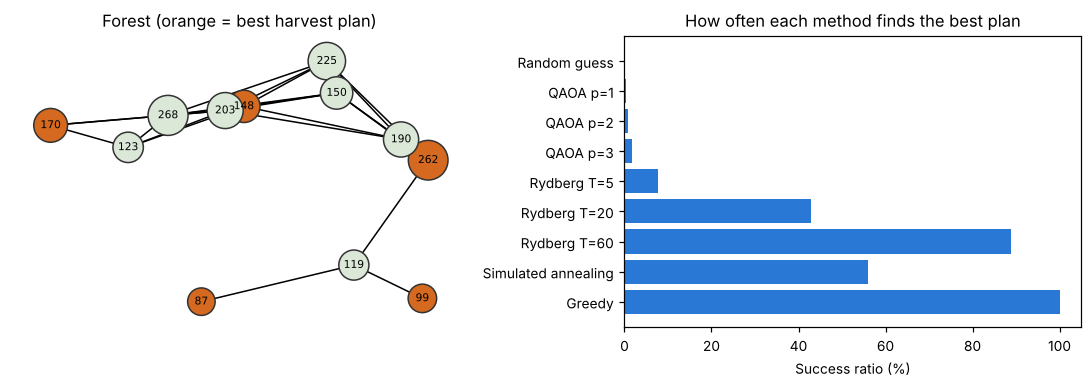

In [3]:
N, SEED, P = 12, 3, 1.0          # change SEED to try another forest
g, vol, pos = small_forest(N, SEED); w = vol / vol.max(); rng = np.random.default_rng(SEED)
B = all_plans(N); vals = B @ w; viol = sum(B[:, i] * B[:, j] for i, j in g.edges())
valid = viol == 0; opt = vals[valid].max(); is_opt = valid & np.isclose(vals, opt)
print(f'{N} stands, {g.number_of_edges()} neighbour pairs, {2**N:,} possible plans')
print(f'Best plan: stands {[int(i) for i in np.where(B[np.argmax(np.where(valid, vals, -1))])[0]]}, '
      f'{opt * vol.max():.0f} m3 of {vol.sum():.0f} m3\n')

rows = [('Random guess', valid.mean(), is_opt.mean())]
cost = -vals + P * viol; warm = None
for p in (1, 2, 3):
    pr, warm = run_qaoa(cost, N, p, rng, warm)
    rows.append((f'QAOA p={p}', pr[valid].sum(), pr[is_opt].sum()))
for T in (5, 20, 60):
    st, val_s, pr = rydberg_sweep(g, w, T)
    rows.append((f'Rydberg sweep T={T}', 1.0, pr[np.isclose(val_s, opt)].sum()))
runs = [simulated_annealing(g, w, P, 100, rng)[0] for _ in range(50)]
rows.append(('Simulated annealing', np.mean([is_valid(g, x) for x in runs]),
             np.mean([is_valid(g, x) and np.isclose(w @ x, opt) for x in runs])))
gx, _ = greedy(g, w); rows.append(('Greedy', 1.0, float(np.isclose(w @ gx, opt))))

print(f"{'Method':22s}{'Valid plans':>12s}{'Success ratio':>15s}{'TTS99':>10s}")
for name, f, o in rows:
    print(f"{name:22s}{100*f:11.1f}%{100*o:14.2f}%{tts99(o):10.1f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
best = B[np.argmax(np.where(valid, vals, -1))]
nx.draw(g, {i: pos[i] for i in range(N)}, ax=ax[0], node_size=150 + vol * 2,
        node_color=['#d4691f' if best[i] else '#dbe8d8' for i in range(N)], edgecolors='#333',
        labels={i: int(vol[i]) for i in range(N)}, font_size=7)
ax[0].set_title('Forest (orange = best harvest plan)')
names = [r[0].replace(' sweep', '') for r in rows]
ax[1].barh(names[::-1], [100 * r[2] for r in rows][::-1], color='#2a78d6')
ax[1].set_xlabel('Success ratio (%)'); ax[1].set_title('How often each method finds the best plan')
plt.tight_layout(); plt.show()

## Part 2 — Classical results matrix
Single-period stand selection on larger forests. Change `SIZES` or `FORESTS_PER_SIZE` for a bigger test (survey v4 used 50–1,000 stands, 10 forests each).

Stands  Method                 Valid  Success  Quality      Time
    50  Exact (MILP)            100%     100%   100.0%    10.8 ms
    50  Greedy                  100%       0%    98.1%     0.2 ms
    50  Tabu search             100%       0%    94.1%    15.6 ms
    50  Simulated annealing     100%       0%    95.3%    50.4 ms
   100  Exact (MILP)            100%     100%   100.0%    10.1 ms
   100  Greedy                  100%       0%    97.7%     0.6 ms
   100  Tabu search             100%       0%    95.2%    31.6 ms
   100  Simulated annealing     100%       0%    93.5%   104.1 ms
   200  Exact (MILP)            100%     100%   100.0%    11.2 ms
   200  Greedy                  100%       0%    96.9%     0.4 ms
   200  Tabu search             100%       0%    95.9%    74.8 ms
   200  Simulated annealing     100%       0%    94.5%   205.2 ms
   500  Exact (MILP)            100%     100%   100.0%    18.3 ms
   500  Greedy                  100%       0%    95.5%     0.7 ms
   500  Tab

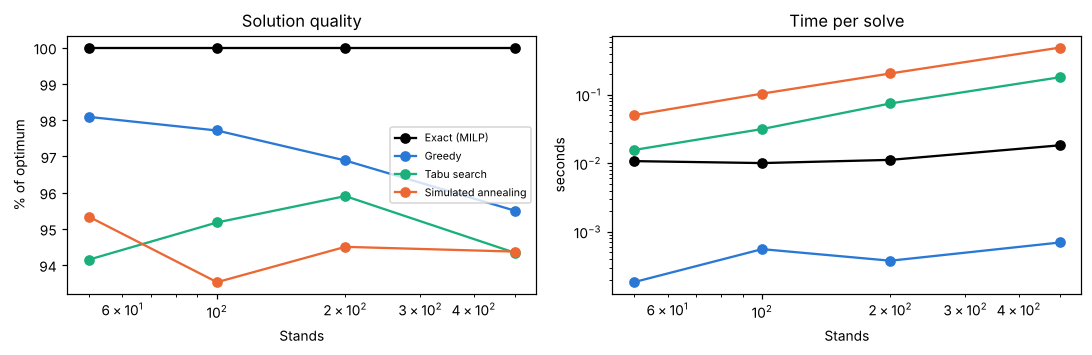

In [4]:
SIZES, FORESTS_PER_SIZE = [50, 100, 200, 500], 3
results = []
for n in SIZES:
    stats = {m: [] for m in ['Exact (MILP)', 'Greedy', 'Tabu search', 'Simulated annealing']}
    for s in range(FORESTS_PER_SIZE):
        g, vol = make_forest(n, seed=100 * n + s); w = vol / vol.max(); rng = np.random.default_rng(s)
        xo, to = exact_milp(g, w); opt = w @ xo
        for name, (x, t) in {'Exact (MILP)': (xo, to), 'Greedy': greedy(g, w),
                             'Tabu search': tabu_search(g, w, 1.5, 20 * n),
                             'Simulated annealing': simulated_annealing(g, w, 1.5, 200, rng)}.items():
            ok = is_valid(g, x); v = w @ x if ok else 0
            stats[name].append((ok, ok and np.isclose(v, opt), v / opt, t))
    for name, st in stats.items():
        a = np.array(st, float)
        results.append((n, name, *a.mean(0)))

print(f"{'Stands':>6s}  {'Method':20s}{'Valid':>8s}{'Success':>9s}{'Quality':>9s}{'Time':>10s}")
for n, name, f, s, q, t in results:
    print(f"{n:6d}  {name:20s}{100*f:7.0f}%{100*s:8.0f}%{100*q:8.1f}%{t*1000:8.1f} ms")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for name, c in zip(['Exact (MILP)', 'Greedy', 'Tabu search', 'Simulated annealing'], ['k', '#2a78d6', '#1baf7a', '#eb6834']):
    r = [x for x in results if x[1] == name]
    ax[0].plot([x[0] for x in r], [100 * x[4] for x in r], 'o-', color=c, label=name)
    ax[1].plot([x[0] for x in r], [x[5] for x in r], 'o-', color=c, label=name)
ax[0].set(xscale='log', xlabel='Stands', ylabel='% of optimum', title='Solution quality')
ax[1].set(xscale='log', yscale='log', xlabel='Stands', ylabel='seconds', title='Time per solve')
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## Part 3 — Complexity: adding the even-flow rule
Five planning periods. Each stand is cut at most once, neighbours not in the same period, and (optionally) each period's harvested volume must stay within ±10% of a target — the **even-flow rule** that keeps mills supplied. `TIME_LIMIT` is per solve, as in survey v4 (30 s). This part takes about 2 minutes.

Stands    Adjacency only      + even flow ±10%


    20           11.2 ms             16.5 s  (optimum proven)


    25            7.2 ms             30.0 s  (time limit: optimum NOT proven)


    50           33.5 ms             30.0 s  (time limit: optimum NOT proven)


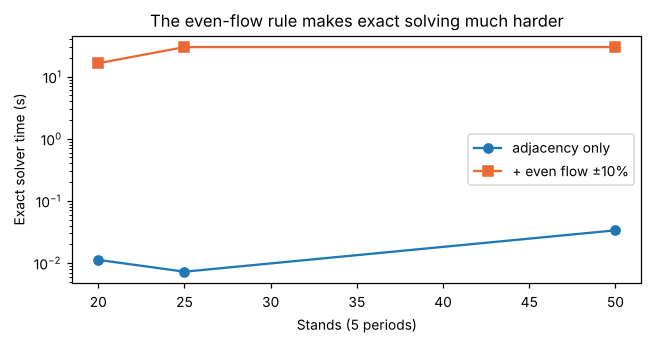

In [5]:
TIME_LIMIT, T = 30, 5
def multi_period(n, seed, band):
    g, vol = make_forest(n, seed)
    growth = 1.02 ** (5 * np.arange(T)); disc = 1.03 ** (-5 * np.arange(T))
    v = np.outer(vol, growth); c = -(v * disc).ravel(); idx = lambda i, t: i * T + t
    rows = n + g.number_of_edges() * T + (T if band else 0)
    A = lil_matrix((rows, n * T)); lb, ub = [], []; k = 0
    for i in range(n):                                   # cut each stand at most once
        for t in range(T): A[k, idx(i, t)] = 1
        lb.append(-np.inf); ub.append(1); k += 1
    for i, j in g.edges():                               # neighbours not in the same period
        for t in range(T):
            A[k, idx(i, t)] = 1; A[k, idx(j, t)] = 1; lb.append(-np.inf); ub.append(1); k += 1
    if band:                                             # even flow: volume within +-band of target
        H = 0.6 * vol.sum() / T * growth / growth.mean()
        for t in range(T):
            for i in range(n): A[k, idx(i, t)] = v[i, t]
            lb.append((1 - band) * H[t]); ub.append((1 + band) * H[t]); k += 1
    t0 = time.perf_counter()
    r = milp(c, constraints=[LinearConstraint(csr_matrix(A[:k]), lb, ub)], integrality=np.ones(n * T),
             bounds=Bounds(0, 1), options={'time_limit': TIME_LIMIT})
    return time.perf_counter() - t0, r.status == 0

print(f"{'Stands':>6s}{'Adjacency only':>18s}{'+ even flow ±10%':>22s}")
out = []
for n in [20, 25, 50]:
    t1, ok1 = multi_period(n, 7000 + 10 * n, None)
    t2, ok2 = multi_period(n, 7000 + 10 * n, 0.10)
    out.append((n, t1, t2, ok2))
    print(f"{n:6d}{t1*1000:15.1f} ms{t2:17.1f} s  {'(optimum proven)' if ok2 else '(time limit: optimum NOT proven)'}")
plt.figure(figsize=(6, 3.2))
plt.plot([o[0] for o in out], [o[1] for o in out], 'o-', label='adjacency only')
plt.plot([o[0] for o in out], [o[2] for o in out], 's-', color='#eb6834', label='+ even flow ±10%')
plt.yscale('log'); plt.xlabel('Stands (5 periods)'); plt.ylabel('Exact solver time (s)'); plt.legend()
plt.title('The even-flow rule makes exact solving much harder'); plt.tight_layout(); plt.show()

## Part 4 — Quantum methods averaged over several forests
`N_FORESTS` controls how many random 12-stand forests are tested (survey v4 used 20; 5 is quicker).

forest 1/5 done


forest 2/5 done


forest 3/5 done


forest 4/5 done


forest 5/5 done

Method                 Valid plans  Success ratio
QAOA p=1                     41.8%           0.4%
QAOA p=2                     70.8%           1.3%
QAOA p=3                     75.3%           3.5%
Rydberg T=20                100.0%          33.9%
Rydberg T=60                100.0%          66.8%
Simulated annealing          94.8%          62.8%
Greedy                      100.0%          80.0%


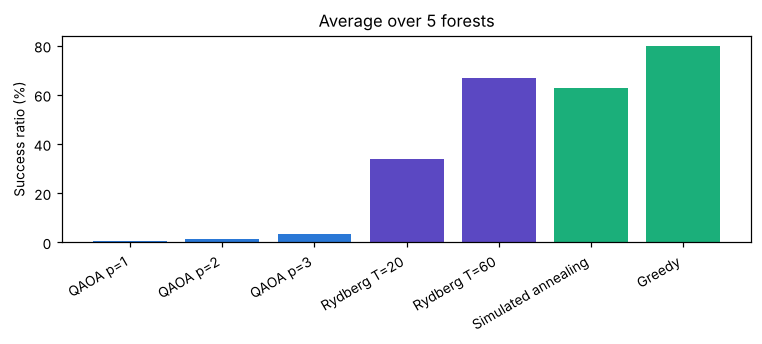

In [6]:
N_FORESTS, N = 5, 12
B = all_plans(N); names = ['QAOA p=1', 'QAOA p=2', 'QAOA p=3', 'Rydberg T=20', 'Rydberg T=60', 'Simulated annealing', 'Greedy']
acc = {k: [] for k in names}
for s in range(N_FORESTS):
    g, vol, _ = small_forest(N, 500 + s); w = vol / vol.max(); rng = np.random.default_rng(s)
    vals = B @ w; viol = sum(B[:, i] * B[:, j] for i, j in g.edges())
    valid = viol == 0; opt = vals[valid].max(); is_opt = valid & np.isclose(vals, opt)
    warm = None
    for p in (1, 2, 3):
        pr, warm = run_qaoa(-vals + viol, N, p, rng, warm)
        acc[f'QAOA p={p}'].append((pr[valid].sum(), pr[is_opt].sum()))
    for T in (20, 60):
        st, val_s, pr = rydberg_sweep(g, w, T); acc[f'Rydberg T={T}'].append((1.0, pr[np.isclose(val_s, opt)].sum()))
    runs = [simulated_annealing(g, w, 1.0, 100, rng)[0] for _ in range(50)]
    acc['Simulated annealing'].append((np.mean([is_valid(g, x) for x in runs]),
                                      np.mean([is_valid(g, x) and np.isclose(w @ x, opt) for x in runs])))
    gx, _ = greedy(g, w); acc['Greedy'].append((1.0, float(np.isclose(w @ gx, opt))))
    print(f'forest {s + 1}/{N_FORESTS} done')

print(f"\n{'Method':22s}{'Valid plans':>12s}{'Success ratio':>15s}")
for k in names:
    a = np.array(acc[k]); print(f"{k:22s}{100*a[:,0].mean():11.1f}%{100*a[:,1].mean():14.1f}%")
plt.figure(figsize=(7, 3.2))
plt.bar(names, [100 * np.mean([x[1] for x in acc[k]]) for k in names],
        color=['#2a78d6'] * 3 + ['#5b48c2'] * 2 + ['#1baf7a'] * 2)
plt.ylabel('Success ratio (%)'); plt.xticks(rotation=30, ha='right')
plt.title(f'Average over {N_FORESTS} forests'); plt.tight_layout(); plt.show()

## Part 5 — Why even flow is the resource problem
Number of QUBO couplings for five periods: sparse adjacency + one-harvest rules versus the dense even-flow rule.

In [7]:
T = 5
print(f"{'Stands':>7s}{'Sparse couplings':>18s}{'Even-flow couplings':>22s}{'Ratio':>8s}")
for n in [50, 200, 1000, 3000]:
    g = nx.random_geometric_graph(n, np.sqrt(5 / (np.pi * n)), seed=1)
    sparse = g.number_of_edges() * T + n * T * (T - 1) // 2
    dense = T * n * (n - 1) // 2
    print(f"{n:7d}{sparse:18,d}{dense:22,d}{dense / sparse:8.0f}")

 Stands  Sparse couplings   Even-flow couplings   Ratio
     50               980                 6,125       6
    200             4,305                99,500      23
   1000            21,805             2,497,500     115
   3000            67,490            22,492,500     333


## Part 6 (optional) — Check the QAOA simulation against Qiskit
Installs Qiskit (about 1 minute) and compares our QAOA state with Qiskit's `QAOAAnsatz` on an 8-stand forest. A fidelity of 1.0000 means the two simulations agree exactly.

In [8]:
!pip install -q qiskit 2>/dev/null
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.circuit.library import QAOAAnsatz
n, P = 8, 1.0
g, vol, _ = small_forest(n, 11); w = vol / vol.max(); E = list(g.edges())
ops = [(''.join('Z' if k == n - 1 - i else 'I' for k in range(n)), w[i] / 2 - P / 4 * sum(i in e for e in E)) for i in range(n)]
ops += [(''.join('Z' if k in (n - 1 - i, n - 1 - j) else 'I' for k in range(n)), P / 4) for i, j in E]
H = SparsePauliOp.from_list(ops).simplify(); ans = QAOAAnsatz(H, reps=1)
gamma, beta = 0.37, 0.81
sv = Statevector(ans.assign_parameters({q: (beta if 'β' in q.name else gamma) for q in ans.parameters})).data
Bn = all_plans(n); cost = -Bn @ w + P * sum(Bn[:, i] * Bn[:, j] for i, j in E)
ours = qaoa_state(np.array([gamma, beta]), cost, 1, n)
print(f'Fidelity between our QAOA and Qiskit: {abs(np.vdot(sv, ours))**2:.4f}')

Fidelity between our QAOA and Qiskit: 1.0000
